# Which station serves which channels, per eruption?

`scripts/survey_channels.py` (plan 0010) asked every station of `eruptions.csv` for a 10-min probe, from 00:00 UTC on each eruption's GVP start date, with `channel="*"`. These are real `get_waveforms` answers, not station metadata: metadata isn't reliable for archived data (plan 0004). A request that failed was recorded as `error` and never retried: that is part of how reliable each service is.

**Data:** `../data/channel_survey.csv` (gitignored; a copy is at `gs://volcan_eye/channel_survey.csv`). One row per channel with data (`status = data`), or one row per station without (`nodata`: the server answered 204 or left it out; `error`: the request failed). `eruptions.csv` gives the station order that `download_windows` uses (question 6).

- **HZ:** a high-rate vertical, `?HZ` at ≥ 20 Hz (the `HZ` slot of ADR-005).
- **LH:** `LHN` or `LHE` (the very-long-period horizontals of the Jerk method).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#bbbbbb"
STATUS_COLOR = {"data": BLUE, "nodata": GREY, "error": ORANGE}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e6", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_rows", 200)

s = pd.read_csv("../data/channel_survey.csv", dtype={"location": str, "detail": str})
s["location"] = s.location.fillna("")  # empty location code, or no channel
s["eruption"] = s.volcano_name + " " + s.start_date
s["hz"] = (s.status == "data") & s.channel.str.fullmatch(r".HZ", na=False) & (s.sampling_rate >= 20)
s["lh"] = (s.status == "data") & s.channel.isin(["LHN", "LHE"])

ERUPTION = ["volcano_number", "volcano_name", "start_date", "eruption"]
STATION = ["volcano_number", "start_date", "client", "network", "station"]
stations = s.drop_duplicates(STATION)  # one row per station asked, per eruption x data center
eruptions = s.groupby(ERUPTION)[["hz", "lh"]].any().reset_index()
eruptions["both"] = eruptions.hz & eruptions.lh
print(f"{len(eruptions)} eruptions, {eruptions.volcano_number.nunique()} volcanoes, "
      f"{len(stations):,} stations asked, {len(s[s.status == 'data']):,} channels with data")

609 eruptions, 143 volcanoes, 62,624 stations asked, 10,785 channels with data


## 1. Request outcome per data center

Each bar is all the stations asked to one data center, over every eruption. Blue answered with data, grey answered without (204, or the station left out of the answer), orange failed. The orange share is how often the service itself failed us.

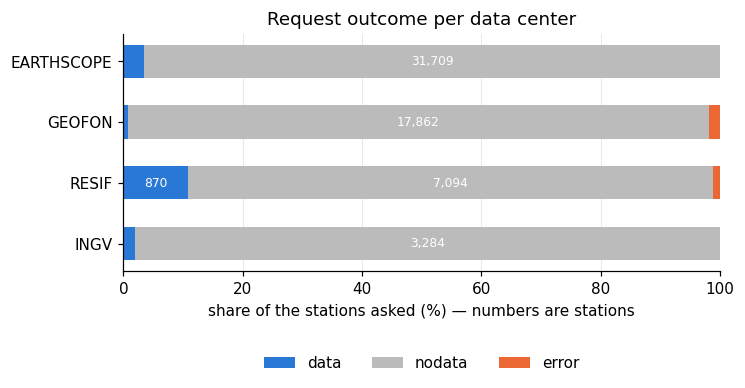

,,stations
client,detail,
GEOFON,FDSNForbiddenException: Authentication failed.,348
RESIF,FDSNRequestTooLargeException: Request would result in too much data. Denied by the datacenter. Split the request in smaller parts,100


In [2]:
out = pd.crosstab(stations.client, stations.status).reindex(columns=["data", "nodata", "error"], fill_value=0)
out = out.loc[out.sum(axis=1).sort_values().index]
share = out.div(out.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(7, 2.8))
left = np.zeros(len(out))
for st in out.columns:
    bars = ax.barh(out.index, share[st] * 100, left=left, color=STATUS_COLOR[st], label=st, height=0.55)
    ax.bar_label(bars, labels=[f"{n:,}" if p > 0.06 else "" for n, p in zip(out[st], share[st])],
                 label_type="center", fontsize=8, color="white")
    left += share[st] * 100
ax.set_xlim(0, 100)
ax.set_xlabel("share of the stations asked (%) — numbers are stations")
ax.set_title("Request outcome per data center")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.3))
plt.show()
errors = stations[stations.status == "error"]
errors.groupby(["client", "detail"]).size().rename("stations").to_frame()

## 2. Eruptions with data

How many eruptions have at least one station that returned an HZ channel, an LH channel, or both (not necessarily at the same station). Bars are eruptions out of the total.

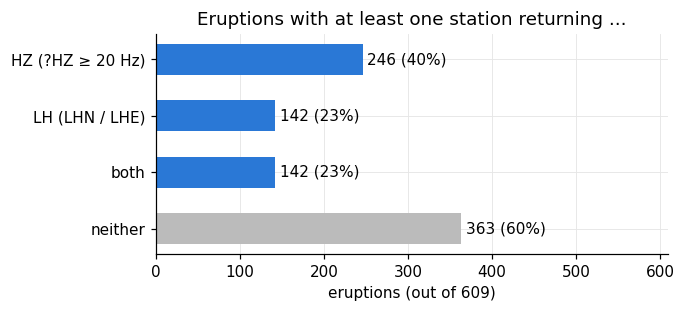

In [3]:
n = pd.Series({"HZ (?HZ ≥ 20 Hz)": eruptions.hz.sum(), "LH (LHN / LHE)": eruptions.lh.sum(),
               "both": eruptions.both.sum(), "neither": (~eruptions.hz & ~eruptions.lh).sum()})
fig, ax = plt.subplots(figsize=(6, 2.6))
bars = ax.barh(n.index, n, color=[BLUE, BLUE, BLUE, GREY], height=0.55)
ax.bar_label(bars, labels=[f"{v} ({v / len(eruptions):.0%})" for v in n], padding=3)
ax.invert_yaxis()
ax.set_xlim(0, len(eruptions))
ax.set_xlabel(f"eruptions (out of {len(eruptions)})")
ax.set_title("Eruptions with at least one station returning ...")
plt.show()

The eruptions with neither an HZ nor an LH channel, per volcano: their start dates, and the channels that stations did return on those dates.

In [4]:
none = eruptions[~eruptions.hz & ~eruptions.lh]
other = s[(s.status == "data") & s.eruption.isin(none.eruption)].groupby("volcano_name").channel.unique().apply(lambda c: ", ".join(sorted(c)[:8]))
none_per_volcano = none.groupby("volcano_name").agg(eruptions=("start_date", "size"),
                                                     start_dates=("start_date", ", ".join))
none_per_volcano["other_channels"] = none_per_volcano.index.map(other).fillna("")
none_per_volcano.sort_values("eruptions", ascending=False)

,eruptions,start_dates,other_channels
volcano_name,,,
Klyuchevskoy,14,"2000-02-03, 2000-07-28, 2002-04-09, 2002-11-24...",
Bezymianny,13,"2000-03-14, 2000-07-18, 2001-07-23, 2001-12-10...",
Kerinci,12,"2001-05-12, 2004-06-22, 2007-09-09, 2009-04-01...",
Marapi,12,"2000-03-11, 2001-04-13, 2004-08-05, 2011-08-03...",
Nyamulagira,10,"2000-01-27, 2001-02-06, 2002-07-25, 2004-05-08...",
Cleveland,10,"2001-02-02, 2005-03-13, 2006-02-06, 2007-06-17...","LXE, LXN, LXZ, MXE, MXN, MXZ"
Copahue,9,"2000-07-01, 2012-07-17, 2012-12-22, 2015-09-18...",
Whakaari/White Island,9,"2000-03-07, 2001-02-19, 2012-08-07, 2016-04-27...",
Sangay,8,"2011-06-06, 2013-01-25, 2015-01-18, 2016-03-17...",


## 3. Channel codes

How many eruptions have at least one station returning each code (top 20). Codes starting with `L`, `V`, `U`, `A`, `O` are low-rate or state-of-health channels.

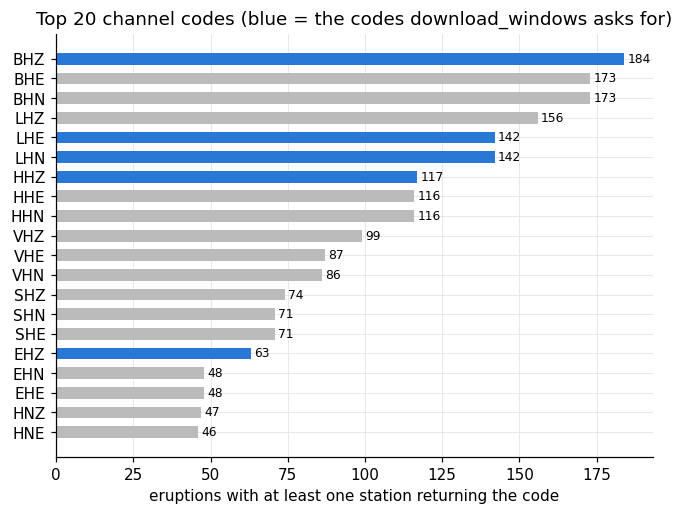

In [5]:
data = s[s.status == "data"]
per_code = data.drop_duplicates(["eruption", "channel"]).channel.value_counts().head(20)
fig, ax = plt.subplots(figsize=(7, 5))
colors = [BLUE if c in ("EHZ", "BHZ", "HHZ", "LHN", "LHE") else GREY for c in per_code.index]
bars = ax.barh(per_code.index, per_code, color=colors, height=0.6)
ax.bar_label(bars, padding=2, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("eruptions with at least one station returning the code")
ax.set_title("Top 20 channel codes (blue = the codes download_windows asks for)")
plt.show()

Sampling rates of the vertical codes. Each cell counts station × eruption pairs, rates rounded to 0.01 Hz: are `BHZ` at 20, 40 or 50 Hz? The `SHZ` / `EHZ` rows show what the "≥ 20 Hz" rule of the HZ slot keeps.

In [6]:
vert = data[data.channel.str.fullmatch(r".HZ")].drop_duplicates(["eruption", "network", "station", "channel", "sampling_rate"])
pd.crosstab(vert.channel, vert.sampling_rate.round(2))  # some report 39.999996 Hz

sampling_rate,0.01,0.10,1.00,8.00,20.00,40.00,50.00,80.00,99.99,100.00,200.00
channel,,,,,,,,,,,
BHZ,0,0,0,0,179,36,156,0,0,6,0
EHZ,0,0,0,0,0,0,0,0,6,572,5
HHZ,0,0,0,0,0,0,19,1,0,1097,11
LHZ,0,0,251,0,0,0,0,0,0,0,0
MHZ,0,0,0,8,0,0,0,0,0,0,0
SHZ,0,0,0,0,0,7,126,0,0,7,0
UHZ,8,0,0,0,0,0,0,0,0,0,0
VHZ,0,132,0,0,0,0,0,0,0,0,0


## 4. Co-located high-rate verticals

Stations that returned two or more of `EHZ` / `BHZ` / `HHZ` in the same probe (any location code). These are the input of the same-station test of ADR-005: the same ground motion seen through two instruments or two rates.

In [7]:
hz3 = data[data.channel.isin(["EHZ", "BHZ", "HHZ"])]
per_sta = hz3.groupby(["eruption", "client", "network", "station"]).apply(
    lambda g: pd.Series({"codes": ", ".join(f"{r.location or '--'}.{r.channel} {r.sampling_rate:g} Hz"
                                            for r in g.sort_values(["channel", "location"]).itertuples()),
                         "n_codes": g.channel.nunique()}), include_groups=False)
coloc = per_sta[per_sta.n_codes >= 2].drop(columns="n_codes")
print(f"{len(coloc)} station x eruption pairs, {coloc.index.get_level_values('eruption').nunique()} eruptions, "
      f"{coloc.reset_index()[['network', 'station']].drop_duplicates().shape[0]} distinct stations")
coloc

138 station x eruption pairs, 46 eruptions, 22 distinct stations


codes
eruption                  client     network station                                                   
Asamayama 2009-01-21      EARTHSCOPE IU      MAJO              00.BHZ 20 Hz, 10.BHZ 40 Hz, 10.HHZ 80 Hz
Axial Seamount 2015-04-23 EARTHSCOPE OO      AXBA1                          --.BHZ 40 Hz, --.HHZ 200 Hz
                                             AXCC1                          --.BHZ 40 Hz, --.HHZ 200 Hz
                                             AXEC2                          --.BHZ 40 Hz, --.HHZ 200 Hz
Dempo 2009-01-01          GEOFON     GE      MNAI                           --.BHZ 20 Hz, --.HHZ 100 Hz
Etna 2010-04-08           INGV       IV      ECNV                           --.BHZ 20 Hz, --.HHZ 100 Hz
                                             ESLN                           --.BHZ 20 Hz, --.HHZ 100 Hz
                                             GALF                           --.BHZ 20 Hz, --.HHZ 100 Hz
                                             MMME                           --.BHZ 20 Hz, --.HHZ 100 Hz
Etna 2010-08-25           INGV       IV      CAGR                           --.BHZ 20 Hz, --.HHZ 100 Hz
                                             ECNV                           --.BHZ 20 Hz, --.HHZ 100 Hz
                                             ESLN                           --.BHZ 20 Hz, --.HHZ 100 Hz
                                             GALF                           --.BHZ 20 Hz, --.HHZ 100 Hz
                                             MMME                           --.BHZ 20 Hz, --.HHZ 100 Hz
Etna 2013-09-03           INGV       IV      ECNV                           --.BHZ 20 Hz, --.HHZ 100 Hz
                                             ESLN                           --.BHZ 20 Hz, --.HHZ 100 Hz
                                             GALF                           --.BHZ 20 Hz, --.HHZ 100 Hz
Etna 2022-11-27           INGV       IV      ESLN                           --.BHZ 20 Hz, --.HHZ 100 Hz
                                             GALF                           --.BHZ 20 Hz, --.HHZ 100 Hz
                                             MUCR                           --.BHZ 20 Hz, --.HHZ 100 Hz
Gamalama 2011-12-05       GEOFON     GE      TNTI                           --.BHZ 20 Hz, --.HHZ 100 Hz
Kilauea 2021-09-29        EARTHSCOPE IU      POHA             00.BHZ 40 Hz, 10.BHZ 40 Hz, 10.HHZ 100 Hz
Kilauea 2024-06-03        EARTHSCOPE HV      AHUD                          --.EHZ 100 Hz, 00.HHZ 100 Hz
                                     IU      POHA             00.BHZ 40 Hz, 10.BHZ 40 Hz, 10.HHZ 100 Hz
                                     PT      KHU                            --.BHZ 40 Hz, --.HHZ 100 Hz
Kilauea 2024-09-15        EARTHSCOPE HV      AHUD                          --.EHZ 100 Hz, 00.HHZ 100 Hz
                                             UWE            QC.EHZ 100 Hz, --.HHZ 100 Hz, QC.HHZ 100 Hz
                                     IU      POHA     00.BHZ 40 Hz, 10.BHZ 40 Hz, 00.HHZ 100 Hz, 10....
                                     PT      KHU                            --.BHZ 40 Hz, --.HHZ 100 Hz
Kilauea 2024-12-23        EARTHSCOPE HV      AHUD                          --.EHZ 100 Hz, 00.HHZ 100 Hz
                                             UWE            QC.EHZ 100 Hz, --.HHZ 100 Hz, QC.HHZ 100 Hz
                                     IU      POHA             00.BHZ 40 Hz, 10.BHZ 40 Hz, 10.HHZ 100 Hz
                                     PT      KHU                            --.BHZ 40 Hz, --.HHZ 100 Hz
Masaya 2008-04-29         GEOFON     NU      MGAN                           --.BHZ 20 Hz, --.HHZ 100 Hz
Masaya 2012-04-30         EARTHSCOPE NU      MASN                           --.BHZ 20 Hz, --.HHZ 100 Hz
                                             MGAN                           --.BHZ 20 Hz, --.HHZ 100 Hz
                          GEOFON     NU      MASN                           --.BHZ 20 Hz, --.HHZ 100 Hz
                                          

## 5. Per volcano

Eruptions surveyed, eruptions with HZ data, with LH data, and the number of distinct stations that returned any data. Sorted by eruptions.

In [8]:
per_volcano = eruptions.groupby("volcano_name").agg(eruptions=("eruption", "size"), with_hz=("hz", "sum"),
                                                     with_lh=("lh", "sum"))
per_volcano["stations_with_data"] = data.drop_duplicates(["volcano_name", "network", "station"]).volcano_name.value_counts()
per_volcano = per_volcano.fillna(0).astype(int).sort_values(["eruptions", "with_hz"], ascending=False)
per_volcano

,eruptions,with_hz,with_lh,stations_with_data
volcano_name,,,,
"Fournaise, Piton de la",30,27,27,95
San Cristobal,24,22,15,23
Klyuchevskoy,18,4,3,50
Bezymianny,17,4,4,14
Telica,16,13,9,26
Poas,13,13,13,23
Raung,12,8,8,2
Kerinci,12,0,0,0
Marapi,12,0,0,0


## 6. Against the CSV order

`download_windows` tries the rows of `eruptions.csv` in file order (after its metadata filter, `operating_rows`, which this survey can't replay) and stops after `MAX_TRIES = 10`. For each eruption with data: how many rows come before the first station with data? Blue counts any channel; orange only stations with a channel `download_windows` asks for (`EHZ`, `BHZ`, `HHZ`, `LHN`, `LHE`). Bars right of the dashed line are eruptions where 10 tries in CSV order never reach a station with data.

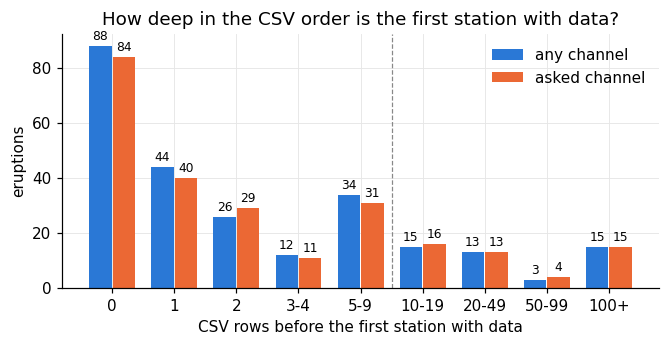

any channel: 250 eruptions with data, first row has data in 88 (35%), beyond the first 10 rows in 46 (18%)
asked channel: 243 eruptions with data, first row has data in 84 (35%), beyond the first 10 rows in 48 (20%)


In [9]:
MAX_TRIES = 10
csv = pd.read_csv("../data/eruptions.csv", index_col=0)
csv = csv.drop_duplicates(["Volcano Number", "Start Date", "Client Name", "Network", "Station"])
csv["rank"] = csv.groupby(["Volcano Number", "Start Date"]).cumcount()  # 0 = first row tried
key = ["Volcano Number", "Start Date", "Client Name", "Network", "Station"]
asked = data.channel.isin(["EHZ", "BHZ", "HHZ", "LHN", "LHE"])
def first_rank(rows):
    k = rows[STATION].set_axis(key, axis=1).drop_duplicates()
    return csv.merge(k, on=key).groupby(["Volcano Number", "Start Date"])["rank"].min()
before = pd.DataFrame({"any channel": first_rank(data), "asked channel": first_rank(data[asked])})
bins = [0, 1, 2, 3, 5, 10, 20, 50, 100, 10_000]
labels = ["0", "1", "2", "3-4", "5-9", "10-19", "20-49", "50-99", "100+"]
fig, ax = plt.subplots(figsize=(7, 3))
x = np.arange(len(labels))
for i, (col, color) in enumerate([("any channel", BLUE), ("asked channel", ORANGE)]):
    c = pd.cut(before[col].dropna(), bins, right=False, labels=labels).value_counts().reindex(labels)
    bars = ax.bar(x + (i - 0.5) * 0.38, c, 0.36, color=color, label=col)
    ax.bar_label(bars, padding=2, fontsize=8)
ax.axvline(4.5, color="#888", lw=0.8, ls="--")
ax.set_xticks(x, labels)
ax.set_xlabel("CSV rows before the first station with data")
ax.set_ylabel("eruptions")
ax.set_title("How deep in the CSV order is the first station with data?")
ax.legend(frameon=False)
plt.show()
for col in before:
    v = before[col].dropna()
    print(f"{col}: {len(v)} eruptions with data, first row has data in {(v == 0).sum()} ({(v == 0).mean():.0%}), "
          f"beyond the first {MAX_TRIES} rows in {(v >= MAX_TRIES).sum()} ({(v >= MAX_TRIES).mean():.0%})")